#### Importing libraries

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statistics

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split


from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

#### Data Loading

In [2]:
titanic = pd.read_csv('titanic.csv')
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


- Numerical Features = Age, Fare, SibSp, Parch
- Categorical Features = Embarked, Sex, Pclass

-- As the assignment is focused on fundamental preprocessing, we are removing unnecessary columns - PassengerId and Ticket. 
- Removing Cabin variable as it contains 687 null entries

In [3]:
df = titanic.drop(['PassengerId','Ticket', 'Cabin'], axis=1)

#### Data Cleaning

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    str    
 3   Sex       891 non-null    str    
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Fare      891 non-null    float64
 8   Embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(3)
memory usage: 62.8 KB


- Checking for duplicates

In [5]:
df.duplicated().sum()

np.int64(0)

#### Handling Missing Values

In [6]:
df.isnull().sum()

Survived      0
Pclass        0
Name          0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

In [7]:
df['Age']= df['Age'].fillna(df['Age'].median())

In [8]:
df = df.astype({'Age':int})

- Since there are 2 missing values in the Embarked variable, we can fill them with the mode 

In [9]:
df['Embarked']= df['Embarked'].fillna(df['Embarked'].mode()[0])

#### Categorical Encoding

- Encoding converts categorical data into numerical representation so that ML algorithms can process it. Since Label encoding works well when the categories have a natural order, we can go for One-hot Encoding

In [10]:
encoder = OneHotEncoder(sparse_output=False,handle_unknown="ignore")

encoded_data = encoder.fit_transform(df[["Sex", "Embarked"]])

encoded_columns = encoder.get_feature_names_out(["Sex", "Embarked"])

df_encoded = pd.DataFrame(encoded_data,columns=encoded_columns,index=df.index).astype(int)

df_encoded.head()

,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0,1,0,0,1
1,1,0,1,0,0
2,1,0,0,0,1
3,1,0,0,0,1
4,0,1,0,0,1


- concatinating both dataframes

In [11]:
df = pd.concat([df, df_encoded], axis=1)

df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0,3,"Braund, Mr. Owen Harris",male,22,1,0,7.2500,S,0,1,0,0,1
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38,1,0,71.2833,C,1,0,1,0,0
2,1,3,"Heikkinen, Miss. Laina",female,26,0,0,7.9250,S,1,0,0,0,1
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35,1,0,53.1000,S,1,0,0,0,1
4,0,3,"Allen, Mr. William Henry",male,35,0,0,8.0500,S,0,1,0,0,1


- Numerical features (Age, Fare, SibSp and Parch) needed to be standardized using StandardScaler to ensure that differences in feature ranges did not disproportionately influence scale-sensitive machine learning algorithms.

- Saving a copy of the dataset as df1 before normalization for further ML process

In [12]:
df1 = df.copy()

In [13]:
columns = ['Age', 'SibSp', 'Parch', 'Fare']
scaler = StandardScaler()
df[columns]=scaler.fit_transform(df[columns])
df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0,3,"Braund, Mr. Owen Harris",male,-0.564145,0.432793,-0.473674,-0.502445,S,0,1,0,0,1
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,0.664649,0.432793,-0.473674,0.786845,C,1,0,1,0,0
2,1,3,"Heikkinen, Miss. Laina",female,-0.256947,-0.474545,-0.473674,-0.488854,S,1,0,0,0,1
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,0.434250,0.432793,-0.473674,0.420730,S,1,0,0,0,1
4,0,3,"Allen, Mr. William Henry",male,0.434250,-0.474545,-0.473674,-0.486337,S,0,1,0,0,1


#### EDA

- Distribution of numerical features

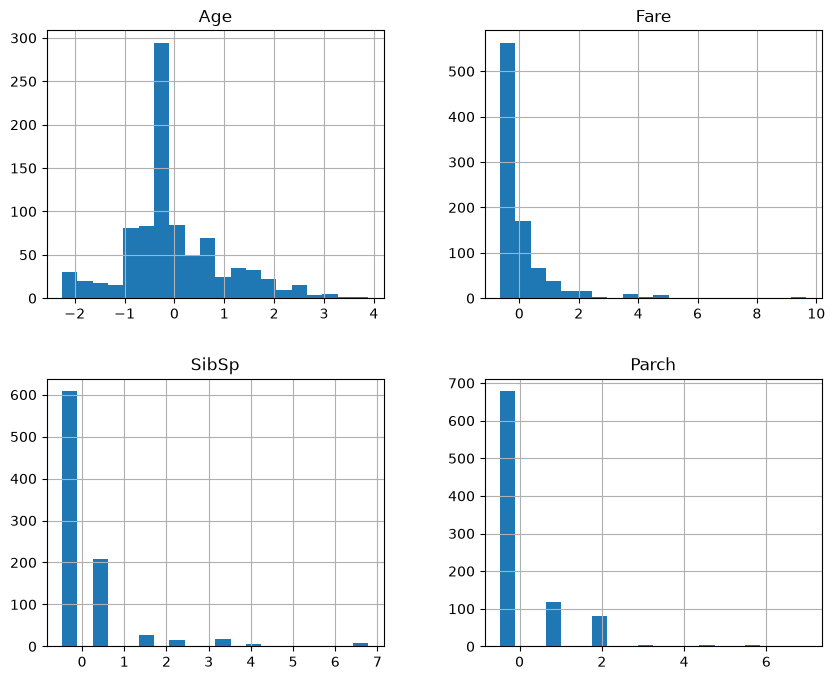

In [14]:
df[["Age","Fare","SibSp","Parch"]].hist(figsize=(10,8), bins=20)
plt.tight_layout
plt.show()

- Survival count

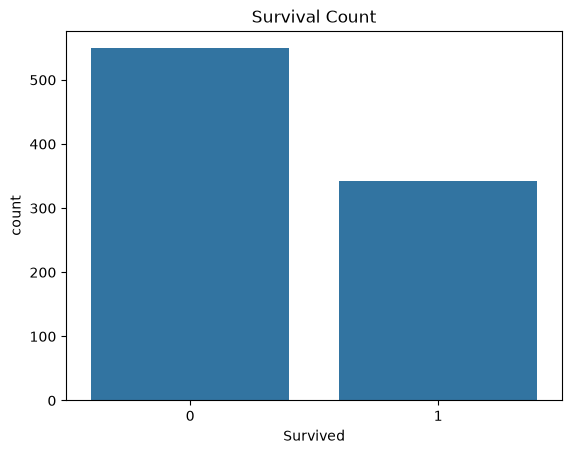

In [15]:
sns.countplot(data=df, x='Survived')
plt.title('Survival Count')
plt.show()

- Survival count by gender

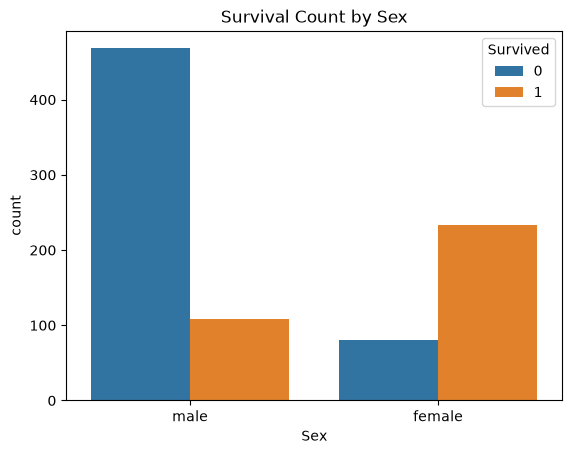

In [16]:
sns.countplot(data=df,x='Sex',hue='Survived')
plt.title('Survival Count by Sex')
plt.show()

- Fare Distribution

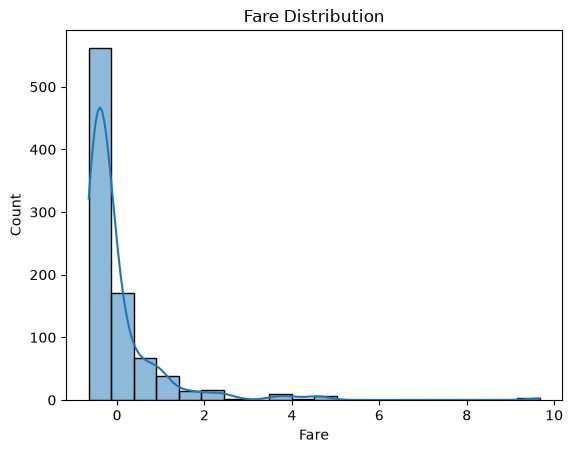

In [17]:
sns.histplot(data =df['Fare'], bins=20, kde=True)
plt.title('Fare Distribution')
plt.show()

- Survival by passenger class

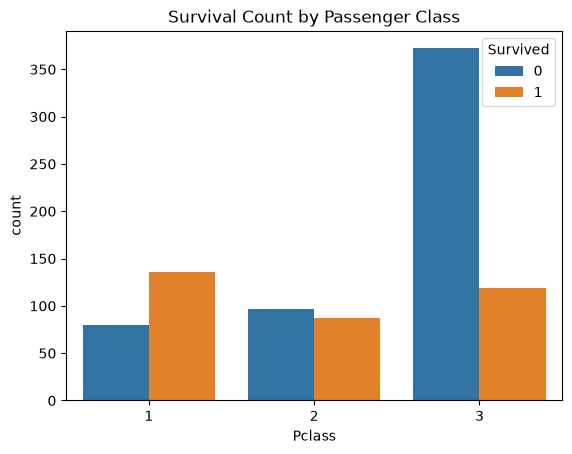

In [18]:
sns.countplot(data=df, x='Pclass', hue='Survived')
plt.title('Survival Count by Passenger Class')
plt.show()

- Before calculating correlation selecting numerical columns

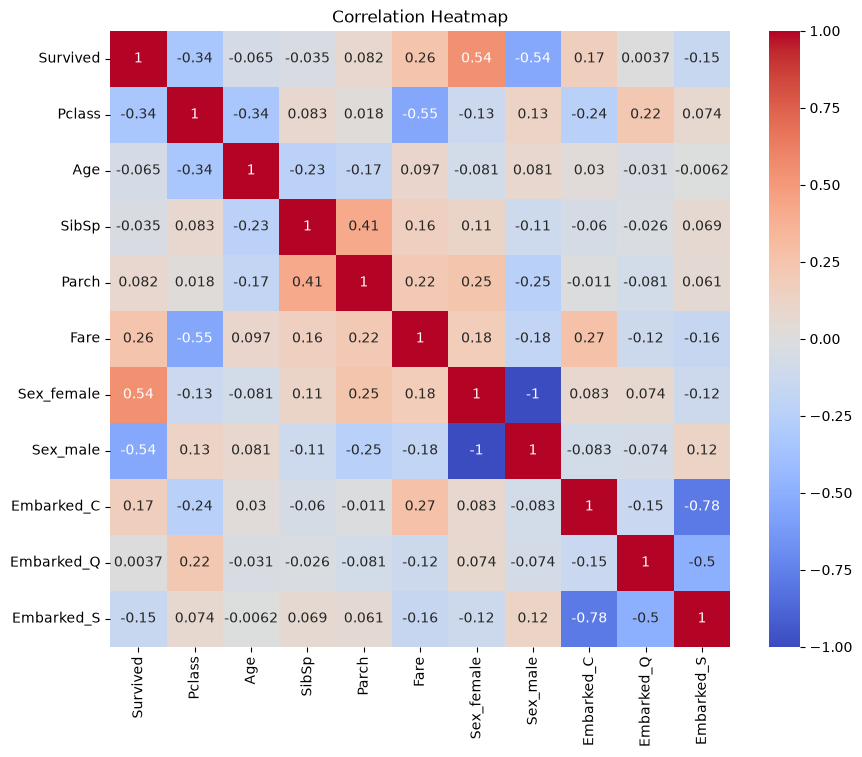

In [19]:
numerical_col = df.select_dtypes(include=np.number)
correlation = numerical_col.corr()
plt.figure(figsize=(10,8))
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

- dropping unnecessary variables

In [26]:
df = df.drop(['Sex', 'Embarked'], axis=1)

## Week 2 Task: Supervised Machine Learning Models

In [27]:
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [28]:
df=titanic.copy()

- Preparing the features and target

In [29]:
# Select relevant input features
features = ["Pclass","Sex","Age","SibSp","Parch","Fare","Embarked"]

X = df[features]
y = df["Survived"]

- Splitting the data

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 712
Testing records: 179


- Preprocessing numerical and categorical features

In [31]:
numerical_features = ["Pclass","Age","SibSp","Parch","Fare"]

categorical_features = ["Sex","Embarked"]

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(handle_unknown="ignore"))])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[("num", numerical_transformer, numerical_features),("cat", categorical_transformer, categorical_features)])

- Training four classification models

In [32]:
models = {"Logistic Regression": LogisticRegression(max_iter=1000),
          "Decision Tree": DecisionTreeClassifier(max_depth=5,random_state=42),
          "Random Forest": RandomForestClassifier(n_estimators=200,random_state=42),
          "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5)}

results = []
trained_models = {}

for model_name, model in models.items():

    # Combine preprocessing and model
    pipeline = Pipeline(steps=[("preprocessor", preprocessor),("model", model)])

    # Train the model
    pipeline.fit(X_train, y_train)

    # Predict test-set outcomes
    y_pred = pipeline.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    y_prob = pipeline.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": auc
    })

    trained_models[model_name] = pipeline

# Display comparison
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(by="F1-Score",ascending=False)

print(results_df.round(3))

                 Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
3  K-Nearest Neighbors     0.816      0.800   0.696     0.744    0.850
2        Random Forest     0.816      0.800   0.696     0.744    0.830
0  Logistic Regression     0.804      0.793   0.667     0.724    0.844
1        Decision Tree     0.765      0.755   0.580     0.656    0.797


- Visualizing model performance

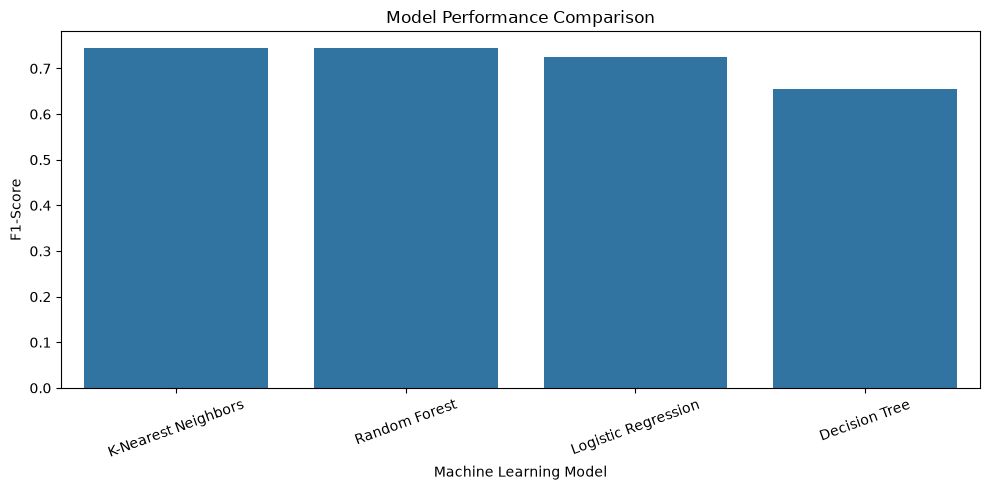

In [33]:
plt.figure(figsize=(10, 5))

sns.barplot(data=results_df,x="Model",y="F1-Score")

plt.title("Model Performance Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("F1-Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

- classification report

In [34]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

y_pred = best_model.predict(X_test)

print("Selected model:", best_model_name)

print(classification_report(y_test,y_pred,target_names=["Did Not Survive", "Survived"],zero_division=0))

Selected model: K-Nearest Neighbors
                 precision    recall  f1-score   support

Did Not Survive       0.82      0.89      0.86       110
       Survived       0.80      0.70      0.74        69

       accuracy                           0.82       179
      macro avg       0.81      0.79      0.80       179
   weighted avg       0.81      0.82      0.81       179



- Confusion Matrix

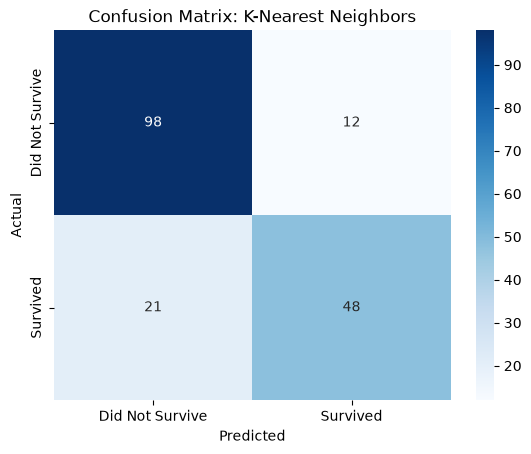

In [35]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=["Did Not Survive", "Survived"],yticklabels=["Did Not Survive", "Survived"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix: {best_model_name}")
plt.show()

## Week 3 Task: Unsupervised Learning & Model Evaluation

- Clustering and Dimensionality Reduction

- For clustering, we will exclude Survived so the algorithm discovers groups without using the survival labels.

In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Select features for clustering
numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Sex", "Embarked"]

features = numeric_features + categorical_features

X = df[features].copy()

# Numerical preprocessing
numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])

# Categorical preprocessing
categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(handle_unknown="ignore"))])

# Combine preprocessing steps
preprocessor = ColumnTransformer([("num", numeric_pipeline, numeric_features),("cat", categorical_pipeline, categorical_features)])

# Transform the data
X_processed = preprocessor.fit_transform(X)

print("Original shape:", X.shape)
print("Processed shape:", X_processed.shape)

Original shape: (891, 7)
Processed shape: (891, 10)


- Implementing K-Means clustering

Clusters: 2, Silhouette Score: 0.3046
Clusters: 3, Silhouette Score: 0.3366
Clusters: 4, Silhouette Score: 0.3193
Clusters: 5, Silhouette Score: 0.3302
Clusters: 6, Silhouette Score: 0.2742
Clusters: 7, Silhouette Score: 0.2756


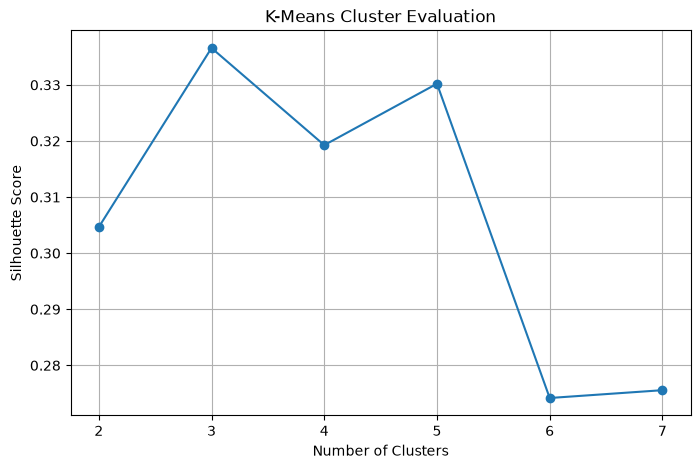

In [37]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Try different cluster counts
silhouette_scores = []

for k in range(2, 8):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_processed)

    score = silhouette_score(X_processed, labels)
    silhouette_scores.append(score)

    print(f"Clusters: {k}, Silhouette Score: {score:.4f}")

# Plot the results
plt.figure(figsize=(8, 5))
plt.plot(range(2, 8), silhouette_scores, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("K-Means Cluster Evaluation")
plt.xticks(range(2, 8))
plt.grid(True)
plt.show()

- Implementing Hierarchical Clustering

In [38]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)

hierarchical_results = []

for k in range(2, 8):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_processed)

    hierarchical_results.append({
        "Clusters": k,
        "Silhouette Score": silhouette_score(X_processed, labels),
        "Calinski-Harabasz Score": calinski_harabasz_score(
            X_processed, labels
        ),
        "Davies-Bouldin Score": davies_bouldin_score(
            X_processed, labels
        )
    })

hierarchical_df = pd.DataFrame(hierarchical_results)

print(hierarchical_df.round(4))

   Clusters  Silhouette Score  Calinski-Harabasz Score  Davies-Bouldin Score
0         2            0.2217                 195.9405                1.8335
1         3            0.2276                 210.8095                1.5070
2         4            0.2336                 202.7366                1.3494
3         5            0.2521                 204.3136                1.3142
4         6            0.2526                 199.2760                1.4265
5         7            0.2248                 193.3108                1.4145


- Compare the clustering algorithms

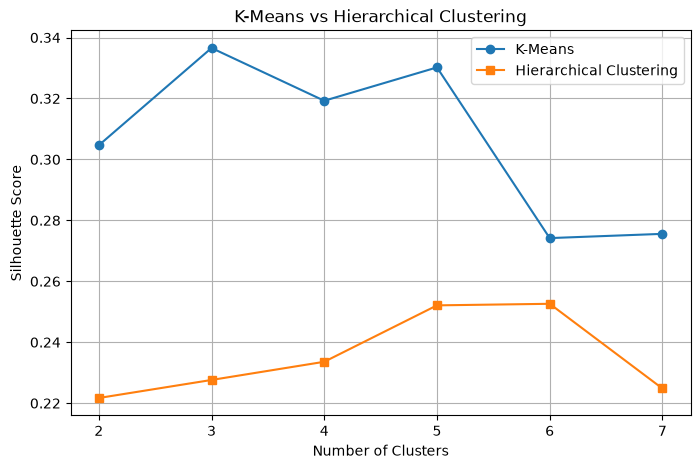

In [39]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 8),silhouette_scores,marker="o",label="K-Means")

plt.plot(hierarchical_df["Clusters"],hierarchical_df["Silhouette Score"],marker="s",label="Hierarchical Clustering")

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("K-Means vs Hierarchical Clustering")
plt.legend()
plt.grid(True)
plt.show()

- Dimensionality reduction using PCA

Variance explained by first two components: 0.5755


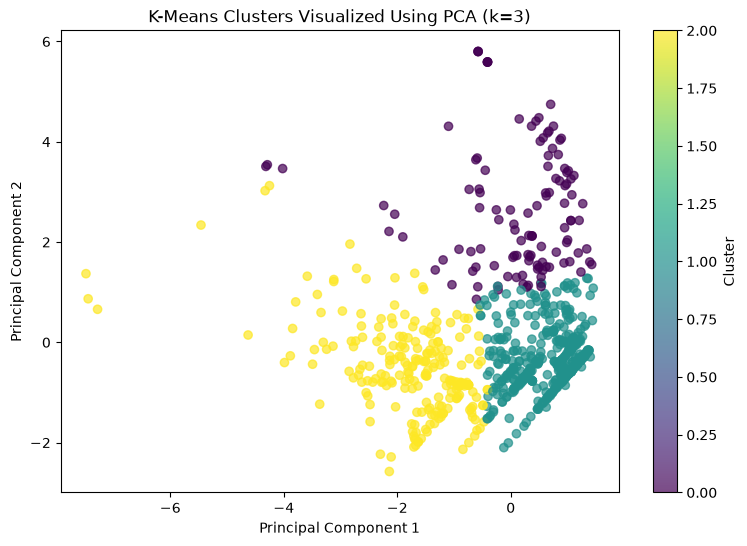

In [40]:
from sklearn.decomposition import PCA

# Select the best K-Means cluster count based on silhouette score
best_k = range(2, 8)[np.argmax(silhouette_scores)]

# Fit the selected K-Means model
best_kmeans = KMeans(n_clusters=best_k,random_state=42,n_init=10)

cluster_labels = best_kmeans.fit_predict(X_processed)

# Reduce features to two dimensions
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_processed)

print(
    "Variance explained by first two components:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

# Visualize clusters
plt.figure(figsize=(9, 6))

plt.scatter(X_pca[:, 0],X_pca[:, 1],c=cluster_labels,alpha=0.7)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(f"K-Means Clusters Visualized Using PCA (k={best_k})")
plt.colorbar(label="Cluster")
plt.show()

- Spliting the data into training and testing sets for Cross-Validation, Evaluation Metrics and Hyperparameter Tuning

In [41]:
# Classification features
X = df[features].copy()

# Target variable
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 712
Testing rows: 179


- Training a Logistic Regression model

In [42]:
from sklearn.linear_model import LogisticRegression

# Create a new preprocessing pipeline
numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])

categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(handle_unknown="ignore"))])

preprocessor = ColumnTransformer([("num", numeric_pipeline, numeric_features),("cat", categorical_pipeline, categorical_features)])

# Combine preprocessing and model
model = Pipeline([("preprocessor", preprocessor),("classifier", LogisticRegression(max_iter=1000))])

# Train model
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Model training and prediction completed.")

Model training and prediction completed.


- Evaluate the model

In [43]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

Accuracy : 0.8045
Precision: 0.7931
Recall   : 0.6667
F1-score : 0.7244
ROC-AUC  : 0.8437


- Generating confusion matrix

Confusion Matrix:
[[98 12]
 [23 46]]


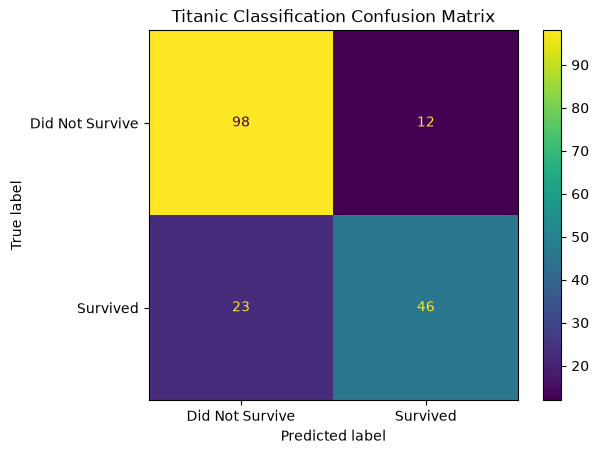

In [44]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Did Not Survive", "Survived"])

display.plot()
plt.title("Titanic Classification Confusion Matrix")
plt.show()

- Ploting the ROC curve

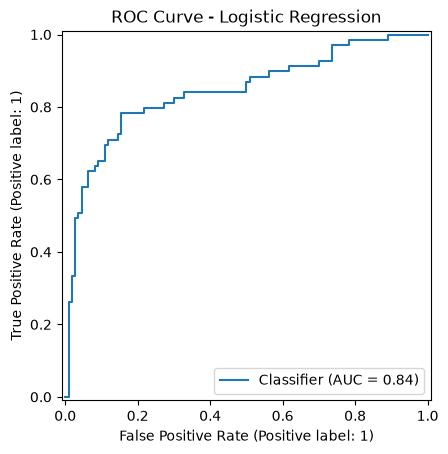

In [45]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test,y_prob)

plt.title("ROC Curve - Logistic Regression")
plt.show()

- Perform 5-fold cross-validation

In [46]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

scoring = {"accuracy": "accuracy","precision": "precision","recall": "recall","f1": "f1","roc_auc": "roc_auc"}

cv_results = cross_validate(model,X_train,y_train,cv=cv,scoring=scoring,n_jobs=-1)

for metric in scoring:
    scores = cv_results[f"test_{metric}"]

    print(
        f"{metric}: Mean = {scores.mean():.4f}, "
        f"Standard Deviation = {scores.std():.4f}"
    )

accuracy: Mean = 0.7963, Standard Deviation = 0.0278
precision: Mean = 0.7531, Standard Deviation = 0.0499
recall: Mean = 0.7034, Standard Deviation = 0.0413
f1: Mean = 0.7260, Standard Deviation = 0.0341
roc_auc: Mean = 0.8551, Standard Deviation = 0.0214


- Performing hyperparameter tuning using GridSearchCV

In [47]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"],
    "classifier__solver": ["liblinear"]
}

grid_search = GridSearchCV(estimator=model,param_grid=param_grid,scoring="f1",cv=cv,n_jobs=-1,refit=True)

# Tune only on training data
grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1-score:")
print(round(grid_search.best_score_, 4))

best_model = grid_search.best_estimator_

# Final evaluation on the held-out test set
best_predictions = best_model.predict(X_test)
best_probabilities = best_model.predict_proba(X_test)[:, 1]

print("\nFinal Test Results:")
print("Accuracy:",
      round(accuracy_score(y_test, best_predictions), 4))

print("Precision:",
      round(precision_score(y_test, best_predictions, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, best_predictions, zero_division=0), 4))

print("F1-score:",
      round(f1_score(y_test, best_predictions, zero_division=0), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, best_probabilities), 4))

Best Parameters:
{'classifier__C': 0.01, 'classifier__class_weight': 'balanced', 'classifier__solver': 'liblinear'}

Best Cross-Validation F1-score:
0.7365

Final Test Results:
Accuracy: 0.7765
Precision: 0.6883
Recall: 0.7681
F1-score: 0.726
ROC-AUC: 0.8353


- model evaluation results

In [48]:
# Save test-set evaluation metrics
evaluation_results = pd.DataFrame([{
    "Model": "Tuned Logistic Regression",
    "Accuracy": accuracy_score(y_test, best_predictions),
    "Precision": precision_score(
        y_test, best_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, best_predictions, zero_division=0
    ),
    "F1_Score": f1_score(
        y_test, best_predictions, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_test, best_probabilities)
}])

# evaluation_results.to_csv("week3_model_evaluation.csv",index=False)

print(evaluation_results.round(4))
print("Evaluation results saved successfully.")

                       Model  Accuracy  Precision  Recall  F1_Score  ROC_AUC
0  Tuned Logistic Regression    0.7765     0.6883  0.7681     0.726   0.8353
Evaluation results saved successfully.


## Week 4 Task: AI Project Deployment & Capstone

In [49]:
import os
import joblib